# CSET485 – AI and Society | Assignment 1
## Adult Census Income dataset — Enrollment suffix: 0988

# CSET485 – AI and Society | Assignment 1
## Adult Census Income dataset — Enrollment suffix: 0988

## Name: Raghav Goel
## enrollment number: S24CSEU0988
## Batch 10

## Btech CSE


## 1. Imports and reproducibility

In [1]:
import sys, warnings, urllib.request
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report

RANDOM_STATE = 988
np.random.seed(RANDOM_STATE)

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 140)
print("Python:", sys.version)
print("Random seed:", RANDOM_STATE)

Python: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
Random seed: 988


## 2. Load the assigned Adult Census Income dataset

The original UCI `adult.data` file has no header row. Missing categorical values are represented by `?`.

In [2]:
DATA_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data"

columns = [
    "age", "workclass", "fnlwgt", "education", "education-num",
    "marital-status", "occupation", "relationship", "race", "sex",
    "capital-gain", "capital-loss", "hours-per-week", "native-country",
    "income"
]

df = pd.read_csv(
    DATA_URL, header=None, names=columns, skipinitialspace=True,
    na_values=["?", " ?"], skip_blank_lines=True
)

# Remove accidental whitespace from string columns
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip()

# Keep only valid binary target labels
df = df[df["income"].isin(["<=50K", ">50K"])].copy()
df["income_binary"] = (df["income"] == ">50K").astype(int)

print("Dataset shape:", df.shape)
display(df.head())
display(df.isna().sum().sort_values(ascending=False).to_frame("missing_values"))

Dataset shape: (32561, 16)


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income,income_binary
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K,0
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K,0
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K,0
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K,0
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K,0


,missing_values
occupation,1843
workclass,1836
native-country,583
fnlwgt,0
education,0
education-num,0
marital-status,0
age,0
relationship,0
race,0


## 3. Preprocessing and train/test split

- Missing categorical values: most-frequent imputation.
- Missing numerical values: median imputation.
- Categorical variables: one-hot encoding; unknown test categories are ignored.
- Numerical variables: standard scaling.
- Outliers: inspect numerical distributions and IQR counts. We retain observations rather than deleting potentially meaningful high-income/capital-gain cases; scaling is used in the model pipeline.
- Split: 70% train, 30% test, `random_state=988`, stratified by income.

The target and raw income label are not used as predictors.

In [3]:
target = "income_binary"
drop_cols = ["income", target]
X = df.drop(columns=drop_cols)
y = df[target].astype(int)

numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(exclude=["number"]).columns.tolist()

numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipe, numeric_features),
    ("cat", categorical_pipe, categorical_features)
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=RANDOM_STATE, stratify=y
)

print("Train rows:", len(X_train), "| Test rows:", len(X_test))
print("Train percentage:", round(100*len(X_train)/len(df), 2))
print("Test percentage:", round(100*len(X_test)/len(df), 2))

# IQR-based outlier counts for documentation (not automatically removed)
outlier_rows = []
for col in numeric_features:
    q1, q3 = X_train[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5*iqr, q3 + 1.5*iqr
    count = ((X_train[col] < low) | (X_train[col] > high)).sum()
    outlier_rows.append([col, low, high, int(count)])
outlier_report = pd.DataFrame(outlier_rows, columns=["feature", "IQR_lower", "IQR_upper", "train_outlier_count"])
display(outlier_report)

Train rows: 22792 | Test rows: 9769
Train percentage: 70.0
Test percentage: 30.0


,feature,IQR_lower,IQR_upper,train_outlier_count
0,age,-2.000,78.000,93
1,fnlwgt,-61822.875,417606.125,673
2,education-num,4.500,16.500,860
3,capital-gain,0.000,0.000,1922
4,capital-loss,0.000,0.000,1076
5,hours-per-week,32.500,52.500,6328


## 4. Part 1 — Build both models

Model A: Linear Regression predicts the numeric income indicator (0/1) using OLS-style least squares.
Model B: Logistic Regression predicts the probability of income greater than $50K.

In [4]:
linear_model = Pipeline([
    ("preprocess", preprocessor),
    ("model", LinearRegression())
])
logistic_model = Pipeline([
    ("preprocess", preprocessor),
    ("model", LogisticRegression(max_iter=2000, solver="liblinear", random_state=RANDOM_STATE))
])

linear_model.fit(X_train, y_train)
logistic_model.fit(X_train, y_train)

linear_pred = linear_model.predict(X_test)
logistic_prob = logistic_model.predict_proba(X_test)[:, 1]

# Required thresholds
linear_threshold = float(np.median(linear_pred))
linear_class = (linear_pred >= linear_threshold).astype(int)
logistic_class = (logistic_prob >= 0.5).astype(int)

comparison_cm = confusion_matrix(linear_class, logistic_class, labels=[0, 1])
mismatch = (linear_class != logistic_class)
mismatch_count = int(mismatch.sum())
mismatch_pct = 100 * mismatch.mean()

print("Median Linear Regression prediction threshold:", linear_threshold)
print("Logistic Regression probability threshold: 0.5")
print("\nConfusion matrix (rows = Linear threshold class; columns = Logistic class):")
display(pd.DataFrame(comparison_cm,
                     index=["Linear low (0)", "Linear high (1)"],
                     columns=["Logistic low (0)", "Logistic high (1)"]))
print(f"Mismatched test cases: {mismatch_count} / {len(X_test)} ({mismatch_pct:.2f}%)")
print("Linear threshold classification accuracy vs true income:", round(accuracy_score(y_test, linear_class), 4))
print("Logistic classification accuracy vs true income:", round(accuracy_score(y_test, logistic_class), 4))

Median Linear Regression prediction threshold: 0.22769439363828534
Logistic Regression probability threshold: 0.5

Confusion matrix (rows = Linear threshold class; columns = Logistic class):


,Logistic low (0),Logistic high (1)
Linear low (0),4874,10
Linear high (1),2992,1893


Mismatched test cases: 3002 / 9769 (30.73%)
Linear threshold classification accuracy vs true income: 0.7135
Logistic classification accuracy vs true income: 0.8515


### Part 1 interpretation prompt

Explain why the two approaches may classify different people. Linear Regression is fitted to a continuous 0/1 target and is thresholded at the *median of its test predictions*, while Logistic Regression estimates probabilities constrained to [0,1] and uses a fixed 0.5 cutoff. Refer to the actual median, confusion matrix, and mismatch percentage printed above.

## 5. Part 2.1 — Subgroup analysis (gender)

Compare the coefficient for `education-num` in the full training data, male subgroup, and female subgroup. All three models use the same preprocessing approach. The coefficient is on the standardized feature scale.

In [5]:
def fit_subgroup_logistic(data_X, data_y, feature_name="education-num"):
    pipe = Pipeline([
        ("preprocess", preprocessor),
        ("model", LogisticRegression(max_iter=2000, solver="liblinear", random_state=RANDOM_STATE))
    ])
    pipe.fit(data_X, data_y)
    feature_names = pipe.named_steps["preprocess"].get_feature_names_out()
    coef = pipe.named_steps["model"].coef_[0]
    matches = [i for i, name in enumerate(feature_names) if name == f"num__{feature_name}"]
    value = float(coef[matches[0]]) if matches else np.nan
    return pipe, value

full_pipe, full_edu_coef = fit_subgroup_logistic(X_train, y_train)

male_mask = X_train["sex"].eq("Male")
female_mask = X_train["sex"].eq("Female")
male_pipe, male_edu_coef = fit_subgroup_logistic(X_train.loc[male_mask], y_train.loc[male_mask])
female_pipe, female_edu_coef = fit_subgroup_logistic(X_train.loc[female_mask], y_train.loc[female_mask])

subgroup_coefficients = pd.DataFrame({
    "model": ["Full training set", "Male subgroup", "Female subgroup"],
    "education-num_coefficient": [full_edu_coef, male_edu_coef, female_edu_coef]
})
display(subgroup_coefficients)
print("Compare coefficient signs and magnitudes. A sign reversal is not guaranteed; if absent, discuss the strength difference.")

,model,education-num_coefficient
0,Full training set,0.708357
1,Male subgroup,0.638792
2,Female subgroup,0.926423


Compare coefficient signs and magnitudes. A sign reversal is not guaranteed; if absent, discuss the strength difference.


## 6. Part 2.2 — Omitted-variable bias

For a transparent stress test, remove `education-num` from the predictor set and compare selected coefficients before/after. The remaining numeric predictors are standardized, so coefficients are comparable on the same scale. This is a deliberate model perturbation, not proof that the removed variable is the only confounder.

In [6]:
def fit_logit_with_features(train_X, train_y, feature_list):
    nums = [c for c in feature_list if c in numeric_features]
    cats = [c for c in feature_list if c in categorical_features]
    prep = ColumnTransformer([
        ("num", Pipeline([("imputer", SimpleImputer(strategy="median")),
                          ("scaler", StandardScaler())]), nums),
        ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                          ("onehot", OneHotEncoder(handle_unknown="ignore"))]), cats)
    ])
    pipe = Pipeline([
        ("preprocess", prep),
        ("model", LogisticRegression(max_iter=2000, solver="liblinear", random_state=RANDOM_STATE))
    ])
    pipe.fit(train_X[feature_list], train_y)
    names = pipe.named_steps["preprocess"].get_feature_names_out()
    coefs = pipe.named_steps["model"].coef_[0]
    return pipe, dict(zip(names, coefs))

full_features = X_train.columns.tolist()
reduced_features = [c for c in full_features if c != "education-num"]
full_omit_pipe, full_coefs = fit_logit_with_features(X_train, y_train, full_features)
reduced_pipe, reduced_coefs = fit_logit_with_features(X_train, y_train, reduced_features)

compare_features = ["age", "hours-per-week", "capital-gain", "capital-loss"]
rows = []
for f in compare_features:
    key = f"num__{f}"
    before = full_coefs.get(key, np.nan)
    after = reduced_coefs.get(key, np.nan)
    pct = (abs(after-before)/abs(before)*100) if before != 0 and np.isfinite(before) and np.isfinite(after) else np.nan
    rows.append([f, before, after, pct])
omitted_variable_table = pd.DataFrame(rows, columns=["predictor", "full_model_coefficient", "reduced_model_coefficient", "absolute_percent_change"])
display(omitted_variable_table)
print("Dropped confounding candidate: education-num")
print("Largest absolute percentage change:", omitted_variable_table.loc[omitted_variable_table["absolute_percent_change"].idxmax()].to_dict())

,predictor,full_model_coefficient,reduced_model_coefficient,absolute_percent_change
0,age,0.300407,0.296926,1.158964
1,hours-per-week,0.360483,0.361017,0.148178
2,capital-gain,2.330353,2.329405,0.040706
3,capital-loss,0.269461,0.269321,0.051932


Dropped confounding candidate: education-num
Largest absolute percentage change: {'predictor': 'age', 'full_model_coefficient': 0.3004072983629483, 'reduced_model_coefficient': 0.2969256861236631, 'absolute_percent_change': 1.1589639327200318}


## 7. Part 2.3 — Adversarial subset: confident wrong predictions

A confident wrong prediction is either probability ≥0.75 with actual class 0, or probability ≤0.25 with actual class 1. Extract up to 50 rows; if more than 50 exist, sample 50 reproducibly.

In [7]:
test_results = X_test.copy()
test_results["actual"] = y_test.to_numpy()
test_results["predicted_probability"] = logistic_prob
test_results["predicted_class"] = logistic_class

false_positive_confident = (test_results["predicted_probability"] >= 0.75) & (test_results["actual"] == 0)
false_negative_confident = (test_results["predicted_probability"] <= 0.25) & (test_results["actual"] == 1)
wrong_mask = false_positive_confident | false_negative_confident
wrong_all = test_results.loc[wrong_mask].copy()

wrong_count = len(wrong_all)
wrong_pct_test = 100 * wrong_count / len(test_results)
adversarial = wrong_all.sample(n=min(50, wrong_count), random_state=RANDOM_STATE) if wrong_count else wrong_all.copy()

print(f"Total confident wrong predictions: {wrong_count} ({wrong_pct_test:.2f}% of test set)")
print("Rows selected for adversarial subset:", len(adversarial))
display(adversarial.head(10))

def demographic_summary(frame, label):
    print(f"\n{label} — age summary")
    display(frame["age"].describe().to_frame().T)
    print(f"{label} — gender proportions")
    display(frame["sex"].value_counts(normalize=True).mul(100).round(2).to_frame("percent"))

demographic_summary(test_results, "Full test set")
if len(adversarial):
    demographic_summary(adversarial, "Adversarial subset")
    print("Adversarial subset categorical profiles:")
    for col in ["race", "workclass", "marital-status", "occupation", "relationship"]:
        print("\n", col)
        display(adversarial[col].value_counts(normalize=True).head(10).mul(100).round(2).to_frame("percent"))
else:
    print("No cases met the specified confidence/error criteria. Report zero and explain that the model produced no such test cases at these cutoffs.")

adversarial.to_csv("adversarial_subset.csv", index=True)

Total confident wrong predictions: 483 (4.94% of test set)
Rows selected for adversarial subset: 50


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,actual,predicted_probability,predicted_class
17358,42,Private,141558,Masters,14,Married-civ-spouse,Prof-specialty,Husband,White,Male,0,0,60,United-States,0,0.774430,1
6910,30,Private,186932,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,70,United-States,0,0.787117,1
13056,35,Private,116541,Masters,14,Never-married,Prof-specialty,Own-child,White,Male,0,0,44,United-States,1,0.062710,0
10356,29,Private,160731,HS-grad,9,Married-civ-spouse,Craft-repair,Husband,White,Male,0,0,45,United-States,1,0.209090,0
18917,47,Private,128796,HS-grad,9,Married-civ-spouse,Craft-repair,Husband,White,Male,0,0,40,United-States,1,0.249058,0
14606,55,Private,147989,Some-college,10,Married-civ-spouse,Craft-repair,Husband,White,Male,5013,0,52,United-States,0,0.806496,1
22491,34,Private,305619,HS-grad,9,Married-civ-spouse,Craft-repair,Husband,White,Male,0,0,40,United-States,1,0.222144,0
6872,52,Private,204322,Assoc-voc,11,Married-civ-spouse,Tech-support,Husband,White,Male,5013,0,40,United-States,0,0.862236,1
12210,33,Private,232475,HS-grad,9,Married-civ-spouse,Craft-repair,Husband,White,Male,0,0,40,United-States,1,0.208785,0
14640,29,State-gov,147256,Assoc-acdm,12,Never-married,Prof-specialty,Not-in-family,Black,Male,0,0,40,United-States,1,0.036628,0



Full test set — age summary


,count,mean,std,min,25%,50%,75%,max
age,9769.0,38.592794,13.74562,17.0,28.0,37.0,47.0,90.0


Full test set — gender proportions


,percent
sex,
Male,67.03
Female,32.97


... (10 outputs left out)


 occupation


,percent
occupation,
Craft-repair,22.92
Prof-specialty,16.67
Exec-managerial,16.67
Machine-op-inspct,10.42
Transport-moving,6.25
Adm-clerical,6.25
Handlers-cleaners,6.25
Protective-serv,4.17
Sales,4.17



 relationship


,percent
relationship,
Husband,66.0
Not-in-family,22.0
Unmarried,4.0
Wife,4.0
Own-child,2.0
Other-relative,2.0


## 8. Part 2.4 — Fairness trade-off analysis by sex

Group A = Male; Group B = Female. For each threshold, calculate:
- DP = selection-rate ratio A/B
- EO = min(TPR_A/TPR_B, FPR_A/FPR_B)
- PP = precision/positive predictive value ratio A/B

A ratio of 1 indicates parity. When a denominator is zero, the ratio is reported as `NaN` rather than silently inventing a value.

,threshold,DP_ratio,EO_ratio,PP_ratio,selection_Male,selection_Female,TPR_Male,TPR_Female,FPR_Male,FPR_Female,PPV_Male,PPV_Female
0,0.05,2.1680,1.0511,1.3641,0.7303,0.3369,0.9910,0.9429,0.6155,0.2630,0.4149,0.3041
1,0.15,3.0803,1.1688,1.0676,0.5805,0.1885,0.9451,0.8086,0.4199,0.1129,0.4978,0.4662
2,0.25,3.2801,1.1986,1.0282,0.4542,0.1385,0.8561,0.7143,0.2772,0.0683,0.5763,0.5605
3,0.35,3.1691,1.1425,1.0144,0.3513,0.1108,0.7443,0.6514,0.1782,0.0449,0.6478,0.6387
4,0.45,3.2640,1.1991,1.0336,0.2807,0.0860,0.6543,0.5457,0.1161,0.0300,0.7127,0.6895
5,0.55,3.1930,1.1687,1.0299,0.2201,0.0689,0.5509,0.4714,0.0744,0.0199,0.7654,0.7432
6,0.65,3.2247,1.1794,1.0291,0.1622,0.0503,0.4381,0.3714,0.0407,0.0111,0.8258,0.8025
7,0.75,3.2971,1.2694,1.0833,0.1136,0.0345,0.3337,0.2629,0.0167,0.0066,0.8978,0.8288
8,0.85,3.4433,1.3403,1.0952,0.0706,0.0205,0.2183,0.1629,0.0055,0.0031,0.9459,0.8636
9,0.95,4.1049,0.6315,1.1016,0.0370,0.0090,0.1194,0.0743,0.0007,0.0010,0.9876,0.8966


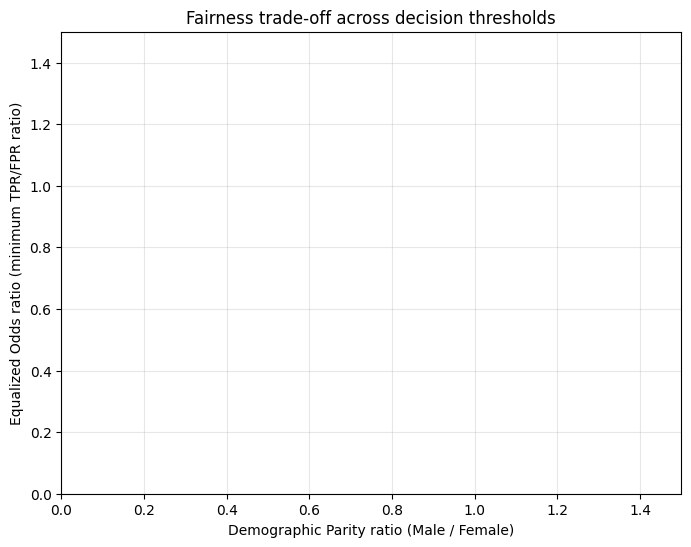

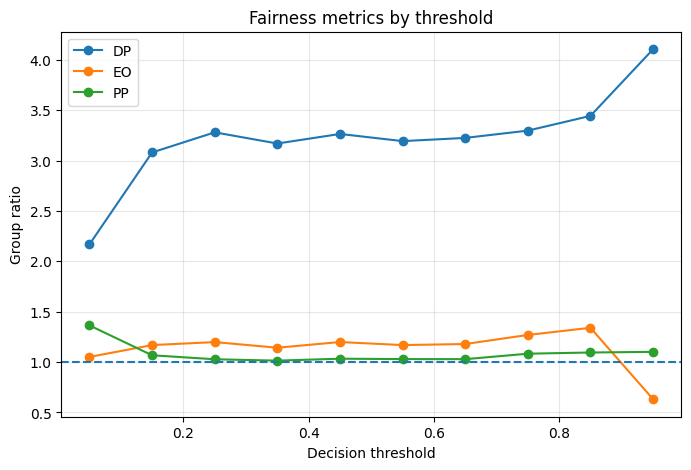

In [8]:
def safe_ratio(a, b):
    if b == 0:
        return np.nan
    return a / b

def group_rates(y_true, y_hat):
    y_true = np.asarray(y_true)
    y_hat = np.asarray(y_hat)
    tp = np.sum((y_true == 1) & (y_hat == 1))
    fn = np.sum((y_true == 1) & (y_hat == 0))
    fp = np.sum((y_true == 0) & (y_hat == 1))
    tn = np.sum((y_true == 0) & (y_hat == 0))
    selection = np.mean(y_hat == 1) if len(y_hat) else np.nan
    tpr = tp/(tp+fn) if (tp+fn) else np.nan
    fpr = fp/(fp+tn) if (fp+tn) else np.nan
    precision = tp/(tp+fp) if (tp+fp) else np.nan
    return selection, tpr, fpr, precision

# Use the untouched test set and the probabilities from Model B
fair_data = X_test[["sex"]].copy()
fair_data["actual"] = y_test.to_numpy()
fair_data["prob"] = logistic_prob

thresholds = np.round(np.arange(0.05, 0.951, 0.10), 2)
fair_rows = []
for t in thresholds:
    pred = (fair_data["prob"].to_numpy() >= t).astype(int)
    a = fair_data["sex"].eq("Male").to_numpy()
    b = fair_data["sex"].eq("Female").to_numpy()
    rates_a = group_rates(fair_data.loc[a, "actual"], pred[a])
    rates_b = group_rates(fair_data.loc[b, "actual"], pred[b])
    dp = safe_ratio(rates_a[0], rates_b[0])
    eo = np.nanmin([safe_ratio(rates_a[1], rates_b[1]), safe_ratio(rates_a[2], rates_b[2])])
    pp = safe_ratio(rates_a[3], rates_b[3])
    fair_rows.append([t, dp, eo, pp,
                      rates_a[0], rates_b[0], rates_a[1], rates_b[1],
                      rates_a[2], rates_b[2], rates_a[3], rates_b[3]])

fairness_table = pd.DataFrame(fair_rows, columns=[
    "threshold", "DP_ratio", "EO_ratio", "PP_ratio",
    "selection_Male", "selection_Female", "TPR_Male", "TPR_Female",
    "FPR_Male", "FPR_Female", "PPV_Male", "PPV_Female"
])
display(fairness_table.round(4))
fairness_table.to_csv("fairness_threshold_results.csv", index=False)

plt.figure(figsize=(8, 6))
plt.scatter(fairness_table["DP_ratio"], fairness_table["EO_ratio"])
for _, row in fairness_table.iterrows():
    if np.isfinite(row["DP_ratio"]) and np.isfinite(row["EO_ratio"]):
        plt.annotate(f'{row["threshold"]:.2f}', (row["DP_ratio"], row["EO_ratio"]),
                     textcoords="offset points", xytext=(5, 5))
plt.xlim(0, 1.5)
plt.ylim(0, 1.5)
plt.xlabel("Demographic Parity ratio (Male / Female)")
plt.ylabel("Equalized Odds ratio (minimum TPR/FPR ratio)")
plt.title("Fairness trade-off across decision thresholds")
plt.grid(True, alpha=0.3)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(fairness_table["threshold"], fairness_table["DP_ratio"], marker="o", label="DP")
plt.plot(fairness_table["threshold"], fairness_table["EO_ratio"], marker="o", label="EO")
plt.plot(fairness_table["threshold"], fairness_table["PP_ratio"], marker="o", label="PP")
plt.axhline(1.0, linestyle="--")
plt.xlabel("Decision threshold")
plt.ylabel("Group ratio")
plt.title("Fairness metrics by threshold")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## 9. Part 3 — Descriptive answers: evidence helper

The assignment requires eight answers of approximately 250–300 words each, and explicitly says generic answers without your own computed numbers receive zero. Use the tables and printed values above to write these answers after running the notebook. This cell prints a compact evidence summary you can use while drafting.

In [9]:
print("=== EVIDENCE SUMMARY ===")
print(f"Test set size: {len(X_test)}")
print(f"Linear prediction median: {linear_threshold:.6f}")
print(f"Mismatch count: {mismatch_count}; mismatch percentage: {mismatch_pct:.3f}%")
print("\nSubgroup coefficients:")
display(subgroup_coefficients)
print("\nOmitted-variable coefficient comparison:")
display(omitted_variable_table)
print(f"\nConfident wrong predictions: {wrong_count} ({wrong_pct_test:.3f}% of test set); sampled subset: {len(adversarial)}")
print("\nFairness table:")
display(fairness_table.round(4))

=== EVIDENCE SUMMARY ===
Test set size: 9769
Linear prediction median: 0.227694
Mismatch count: 3002; mismatch percentage: 30.730%

Subgroup coefficients:


,model,education-num_coefficient
0,Full training set,0.708357
1,Male subgroup,0.638792
2,Female subgroup,0.926423



Omitted-variable coefficient comparison:


,predictor,full_model_coefficient,reduced_model_coefficient,absolute_percent_change
0,age,0.300407,0.296926,1.158964
1,hours-per-week,0.360483,0.361017,0.148178
2,capital-gain,2.330353,2.329405,0.040706
3,capital-loss,0.269461,0.269321,0.051932



Confident wrong predictions: 483 (4.944% of test set); sampled subset: 50

Fairness table:


,threshold,DP_ratio,EO_ratio,PP_ratio,selection_Male,selection_Female,TPR_Male,TPR_Female,FPR_Male,FPR_Female,PPV_Male,PPV_Female
0,0.05,2.1680,1.0511,1.3641,0.7303,0.3369,0.9910,0.9429,0.6155,0.2630,0.4149,0.3041
1,0.15,3.0803,1.1688,1.0676,0.5805,0.1885,0.9451,0.8086,0.4199,0.1129,0.4978,0.4662
2,0.25,3.2801,1.1986,1.0282,0.4542,0.1385,0.8561,0.7143,0.2772,0.0683,0.5763,0.5605
3,0.35,3.1691,1.1425,1.0144,0.3513,0.1108,0.7443,0.6514,0.1782,0.0449,0.6478,0.6387
4,0.45,3.2640,1.1991,1.0336,0.2807,0.0860,0.6543,0.5457,0.1161,0.0300,0.7127,0.6895
5,0.55,3.1930,1.1687,1.0299,0.2201,0.0689,0.5509,0.4714,0.0744,0.0199,0.7654,0.7432
6,0.65,3.2247,1.1794,1.0291,0.1622,0.0503,0.4381,0.3714,0.0407,0.0111,0.8258,0.8025
7,0.75,3.2971,1.2694,1.0833,0.1136,0.0345,0.3337,0.2629,0.0167,0.0066,0.8978,0.8288
8,0.85,3.4433,1.3403,1.0952,0.0706,0.0205,0.2183,0.1629,0.0055,0.0031,0.9459,0.8636
9,0.95,4.1049,0.6315,1.1016,0.0370,0.0090,0.1194,0.0743,0.0007,0.0010,0.9876,0.8966


## 10. Part 4 — Reflection evidence

Write the approximately 500-word reflection only after inspecting your computed evidence. Address:
1. Deploy, conditionally deploy, or reject.
2. At least three limitations of a single-number answer (subgroup gaps, threshold choice, fairness conflicts, confident failures, omitted confounds).
3. Cite exact values from your own outputs.
4. Close by explaining why responsible deployment requires transparency about trade-offs.

## 11. Save reproducibility outputs

The notebook itself is the reproducible code deliverable. The following cell saves the main analysis tables as CSV files.

In [10]:
comparison_table = pd.DataFrame({
    "metric": ["linear_median_threshold", "mismatch_count", "mismatch_percentage",
               "linear_accuracy", "logistic_accuracy", "confident_wrong_count",
               "confident_wrong_percentage_test"],
    "value": [linear_threshold, mismatch_count, mismatch_pct,
              accuracy_score(y_test, linear_class), accuracy_score(y_test, logistic_class),
              wrong_count, wrong_pct_test]
})
comparison_table.to_csv("part1_comparison_summary.csv", index=False)
subgroup_coefficients.to_csv("part2_1_subgroup_coefficients.csv", index=False)
omitted_variable_table.to_csv("part2_2_omitted_variable.csv", index=False)
print("Saved: adversarial_subset.csv, fairness_threshold_results.csv,")
print("       part1_comparison_summary.csv, part2_1_subgroup_coefficients.csv,")
print("       part2_2_omitted_variable.csv")

Saved: adversarial_subset.csv, fairness_threshold_results.csv,
       part1_comparison_summary.csv, part2_1_subgroup_coefficients.csv,
       part2_2_omitted_variable.csv
